# 06 — Margens de segurança e custo assimétrico de decisão

Este notebook avalia, em previsões walk-forward já fora da amostra, quanto diferentes margens alterariam uma quantidade de produção simulada. A margem dinâmica é estimada exclusivamente com erros de folds anteriores da mesma série de previsões; não consulta os resultados do fold corrente.

**As razões de penalidade são cenários hipotéticos**, não custos observados. Sem quantidade efetivamente produzida, refeições servidas, sobras e faltas, excesso/falta previstos continuam sendo desvios simulados, não desperdício ou desatendimento reais. Este notebook não escolhe nem congela automaticamente um campeão operacional.


In [1]:
from pathlib import Path
import os
import tempfile
import math
import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mplconfig_novo_experimento"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
root_candidates = [cwd, cwd.parent, cwd / "NOVO_EXPERIMENTO"]
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "reservas_consumo_cardapio_calendario_clima"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
assert ROOT is not None, f"Não localizei a raiz de NOVO_EXPERIMENTO a partir de {cwd}."
SOURCE = LINE_RESULTS / "05_ablation_grupos_features" / "previsoes_ablation_completo_baselines.csv"
OUT = LINE_RESULTS / "06_margens_seguranca"
OUT.mkdir(parents=True, exist_ok=True)

assert SOURCE.exists(), f"Arquivo de previsões do Notebook 05 não encontrado: {SOURCE}"
raw = pd.read_csv(SOURCE)
required = {"fold", "origem", "data", "modelo", "modelo_original", "condicao", "consumo_real", "previsao"}
missing = required - set(raw.columns)
assert not missing, f"Colunas obrigatórias ausentes: {sorted(missing)}"

raw["data"] = pd.to_datetime(raw["data"], format="mixed", errors="raise")
raw["origem"] = pd.to_datetime(raw["origem"], format="mixed", errors="raise")
raw["fold"] = pd.to_numeric(raw["fold"], errors="raise").astype(int)
raw["consumo_real"] = pd.to_numeric(raw["consumo_real"], errors="raise")
raw["previsao"] = pd.to_numeric(raw["previsao"], errors="raise")
raw["metodo"] = raw["condicao"].astype(str) + "::" + raw["modelo_original"].astype(str)

assert raw[["consumo_real", "previsao"]].notna().all().all(), "Há alvo/previsão ausente."
assert np.isfinite(raw[["consumo_real", "previsao"]].to_numpy()).all(), "Há valor não finito."
assert (raw["data"] > raw["origem"]).all(), "Há previsão associada a data não futura da origem."
assert not raw.duplicated(["metodo", "data"]).any(), "Há mais de uma previsão por método/data."

# Interseção estrita para comparar todos os métodos nas mesmas datas (inclui Prophet).
date_sets = raw.groupby("metodo")["data"].apply(lambda s: set(s))
common_dates = set.intersection(*date_sets.tolist())
df = raw.loc[raw["data"].isin(common_dates)].copy()
assert len(common_dates) > 0 and df["metodo"].nunique() == raw["metodo"].nunique()
print(f"{df['metodo'].nunique()} métodos; {len(common_dates)} datas comuns; {df['fold'].nunique()} origens/folds.")
print(f"Datas excluídas da comparação pareada por indisponibilidade em algum método: {raw['data'].nunique() - len(common_dates)}.")


65 métodos; 432 datas comuns; 102 origens/folds.
Datas excluídas da comparação pareada por indisponibilidade em algum método: 7.


## Políticas e regra temporal

São comparadas margens fixas de 0, 5, 10, 15 e 20 refeições, além de quantis 50, 75 e 90 dos erros positivos `consumo real − previsão` observados nos folds anteriores. Os quantis dinâmicos ficam em zero até haver ao menos 21 erros anteriores (aproximadamente três origens semanais). Margens dinâmicas negativas são limitadas a zero.

A quantidade simulada é arredondada para cima, pois refeições são unidades inteiras. Para explicitar a assimetria, cada falta recebe peso relativo 1, 2, 3 ou 5, enquanto o excesso recebe peso 1. São análises de sensibilidade; não há evidência local para afirmar qual razão representa os custos ou consequências reais.


In [2]:
FIXED_MARGINS = [0, 5, 10, 15, 20]
QUANTILES = {"prequential_q50": 0.50, "prequential_q75": 0.75, "prequential_q90": 0.90}
SHORTAGE_TO_EXCESS_RATIOS = [1, 2, 3, 5]
MIN_PRIOR_ERRORS = 21

parts = []
for method, group in df.groupby("metodo", sort=False):
    group = group.sort_values(["fold", "data"]).copy()
    prior_residuals = []
    for fold, fold_rows in group.groupby("fold", sort=True):
        # Margens para este fold usam exclusivamente folds estritamente anteriores.
        rows = fold_rows.copy()
        cutoff = pd.to_datetime(rows["origem"]).min()
        prior_rows = group.loc[pd.to_datetime(group["data"]).lt(cutoff)]
        prior_residuals = (prior_rows["consumo_real"] - prior_rows["previsao"]).tolist()
        assert prior_rows.empty or pd.to_datetime(prior_rows["data"]).max() < cutoff
        rows["residuo_prequential"] = rows["consumo_real"] - rows["previsao"]
        rows["metodo"] = method
        for margin in FIXED_MARGINS:
            rows[f"margem_fixa_{margin}"] = float(margin)
        for policy, q in QUANTILES.items():
            if len(prior_residuals) >= MIN_PRIOR_ERRORS:
                margin = max(0.0, float(np.quantile(prior_residuals, q)))
            else:
                margin = 0.0
            rows[policy] = margin
        parts.append(rows)
        # O histórico será novamente filtrado por data < origem no próximo fold.

calibrated = pd.concat(parts, ignore_index=True)
policy_columns = [f"margem_fixa_{m}" for m in FIXED_MARGINS] + list(QUANTILES)
long = calibrated.melt(
    id_vars=["fold", "origem", "data", "ano", "metodo", "modelo", "modelo_original", "condicao", "familia", "consumo_real", "previsao", "residuo_prequential"],
    value_vars=policy_columns,
    var_name="politica_margem",
    value_name="margem_refeicoes",
)
long["previsao_base_nao_negativa"] = long["previsao"].clip(lower=0)
long["quantidade_simulada"] = np.ceil(long["previsao_base_nao_negativa"] + long["margem_refeicoes"]).astype(int)
long["excesso_simulado"] = (long["quantidade_simulada"] - long["consumo_real"]).clip(lower=0)
long["falta_simulada"] = (long["consumo_real"] - long["quantidade_simulada"]).clip(lower=0)
long["erro_abs_consumo"] = (long["consumo_real"] - long["previsao"]).abs()
long["erro_abs_decisao"] = (long["consumo_real"] - long["quantidade_simulada"]).abs()


In [3]:
def summarize(frame: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    records = []
    for keys, g in frame.groupby(group_cols, dropna=False, sort=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        rec = dict(zip(group_cols, keys))
        n = len(g)
        total_actual = float(g["consumo_real"].sum())
        rec.update({
            "n_datas": n,
            "MAE_consumo": float(g["erro_abs_consumo"].mean()),
            "WAPE_consumo_pct": float(g["erro_abs_consumo"].sum() / total_actual * 100) if total_actual else np.nan,
            "margem_media": float(g["margem_refeicoes"].mean()),
            "excesso_total_simulado": float(g["excesso_simulado"].sum()),
            "falta_total_simulada": float(g["falta_simulada"].sum()),
            "excesso_medio_dia": float(g["excesso_simulado"].mean()),
            "falta_media_dia": float(g["falta_simulada"].mean()),
            "dias_com_excesso_pct": float((g["excesso_simulado"] > 0).mean() * 100),
            "dias_com_falta_pct": float((g["falta_simulada"] > 0).mean() * 100),
            "cobertura_demanda_pct": float((g["quantidade_simulada"] >= g["consumo_real"]).mean() * 100),
            "erro_abs_decisao_medio": float(g["erro_abs_decisao"].mean()),
        })
        records.append(rec)
    return pd.DataFrame(records)

base_keys = ["metodo", "politica_margem"]
decision = long.merge(
    pd.DataFrame({"razao_penalidade_falta_sobra": SHORTAGE_TO_EXCESS_RATIOS}),
    how="cross",
)
decision["perda_relativa_total"] = (
    decision["excesso_simulado"]
    + decision["falta_simulada"] * decision["razao_penalidade_falta_sobra"]
)
overall = summarize(decision, base_keys + ["razao_penalidade_falta_sobra"])
loss = decision.groupby(base_keys + ["razao_penalidade_falta_sobra"], as_index=False).agg(
    perda_relativa_total=("perda_relativa_total", "sum"),
)
overall = overall.merge(loss, on=base_keys + ["razao_penalidade_falta_sobra"], validate="one_to_one")
overall["perda_relativa_media_dia"] = overall["perda_relativa_total"] / overall["n_datas"]

annual = summarize(decision, base_keys + ["razao_penalidade_falta_sobra", "ano"])
annual_loss = decision.groupby(base_keys + ["razao_penalidade_falta_sobra", "ano"], as_index=False).agg(
    perda_relativa_total=("perda_relativa_total", "sum"),
)
annual = annual.merge(annual_loss, on=base_keys + ["razao_penalidade_falta_sobra", "ano"], validate="one_to_one")
annual["perda_relativa_media_dia"] = annual["perda_relativa_total"] / annual["n_datas"]

zero = overall.loc[overall["politica_margem"] == "margem_fixa_0", base_keys[:1] + ["razao_penalidade_falta_sobra", "perda_relativa_media_dia", "falta_media_dia", "excesso_medio_dia"]].rename(columns={
    "perda_relativa_media_dia": "perda_media_sem_margem",
    "falta_media_dia": "falta_media_sem_margem",
    "excesso_medio_dia": "excesso_medio_sem_margem",
})
overall = overall.merge(zero, on=["metodo", "razao_penalidade_falta_sobra"], validate="many_to_one")
overall["reducao_perda_pct_vs_sem_margem"] = np.where(
    overall["perda_media_sem_margem"] > 0,
    (overall["perda_media_sem_margem"] - overall["perda_relativa_media_dia"]) / overall["perda_media_sem_margem"] * 100,
    np.nan,
)

out_general = OUT / "metricas_margens.csv"
out_annual = OUT / "metricas_margens_por_ano.csv"
out_predictions = OUT / "previsoes_decisao_margens.csv"
overall.to_csv(out_general, index=False, encoding="utf-8-sig")
annual.to_csv(out_annual, index=False, encoding="utf-8-sig")
decision.to_csv(out_predictions, index=False, encoding="utf-8-sig")

# Ranking exploratório: os melhores da própria janela não são seleção independente.
leaders = (
    overall.sort_values(["razao_penalidade_falta_sobra", "perda_relativa_media_dia", "MAE_consumo"])
    .groupby("razao_penalidade_falta_sobra", as_index=False, group_keys=False)
    .head(10)
)
leaders.to_csv(OUT / "melhores_cenarios_exploratorios.csv", index=False, encoding="utf-8-sig")
print(f"Salvos: {out_general.name}, {out_annual.name}, {out_predictions.name}; {len(overall):,} combinações método/política/razão.")


Salvos: metricas_margens.csv, metricas_margens_por_ano.csv, previsoes_decisao_margens.csv; 2,080 combinações método/política/razão.


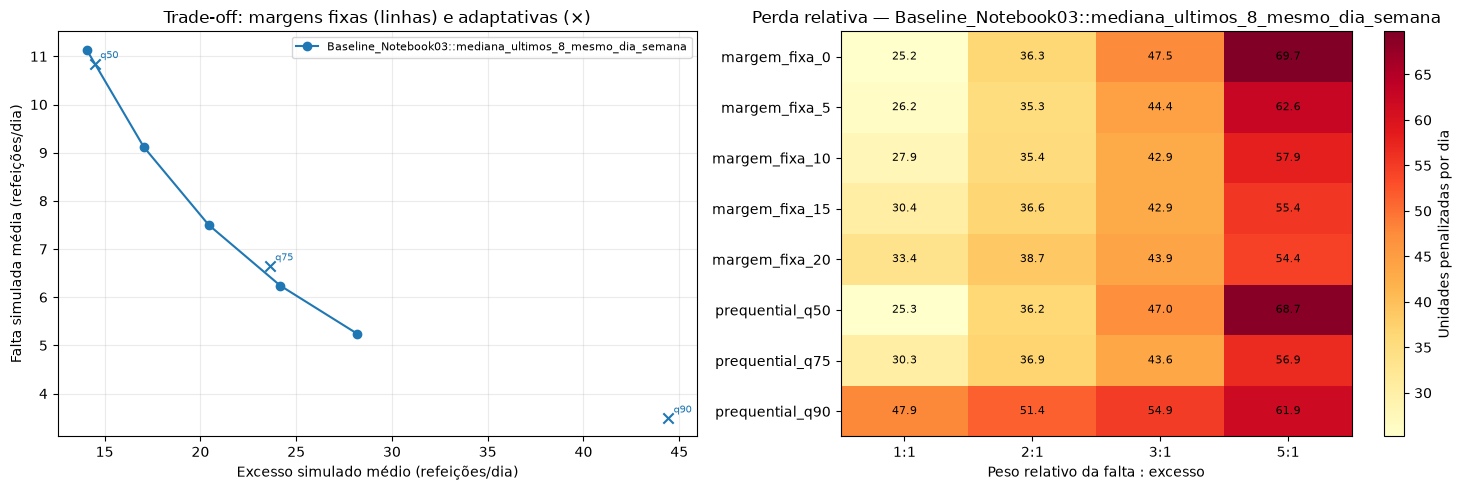

Gráfico salvo em F:\PRODUTO_MESTRADO\resultados\linhas\reservas_consumo_cardapio_calendario_clima\06_margens_seguranca\tradeoff_margens_e_penalidades.png.


In [4]:
# Referências para visualizar trade-off sem esconder a variação entre política base e propostas.
reference_methods = [
    "Baseline_Notebook03::mediana_ultimos_8_mesmo_dia_semana",
    "Completo_Notebook04::ExtraTrees",
    "Historico_Calendario::Ensemble_ponderado_validacao",
]
available_refs = [m for m in reference_methods if m in set(overall["metodo"])]
chart = overall.loc[
    overall["metodo"].isin(available_refs)
    & overall["razao_penalidade_falta_sobra"].isin([1, 2, 5])
].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for method in available_refs:
    subset = chart[(chart["metodo"] == method) & (chart["razao_penalidade_falta_sobra"] == 1)]
    fixed = subset[subset["politica_margem"].str.startswith("margem_fixa_")].copy()
    fixed["margem_num"] = fixed["politica_margem"].str.removeprefix("margem_fixa_").astype(int)
    fixed = fixed.sort_values("margem_num")
    (line,) = axes[0].plot(fixed["excesso_medio_dia"], fixed["falta_media_dia"], marker="o", label=method)
    dynamic = subset[subset["politica_margem"].isin(QUANTILES)].copy()
    axes[0].scatter(dynamic["excesso_medio_dia"], dynamic["falta_media_dia"], marker="x", s=55, color=line.get_color())
    for _, point in dynamic.iterrows():
        axes[0].annotate(point["politica_margem"].replace("prequential_q", "q"),
                         (point["excesso_medio_dia"], point["falta_media_dia"]),
                         xytext=(4, 4), textcoords="offset points", fontsize=7, color=line.get_color())
axes[0].set_xlabel("Excesso simulado médio (refeições/dia)")
axes[0].set_ylabel("Falta simulada média (refeições/dia)")
axes[0].set_title("Trade-off: margens fixas (linhas) e adaptativas (×)")
axes[0].grid(alpha=.25)
axes[0].legend(fontsize=8)

focus_method = "Historico_Calendario::Ensemble_ponderado_validacao"
if focus_method not in set(overall["metodo"]):
    focus_method = available_refs[0]
heat = overall.loc[overall["metodo"] == focus_method].pivot(
    index="politica_margem", columns="razao_penalidade_falta_sobra", values="perda_relativa_media_dia"
)
heat = heat.reindex(policy_columns)
im = axes[1].imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd")
axes[1].set_xticks(range(len(heat.columns)), [f"{x}:1" for x in heat.columns])
axes[1].set_yticks(range(len(heat.index)), heat.index)
axes[1].set_xlabel("Peso relativo da falta : excesso")
axes[1].set_title(f"Perda relativa — {focus_method}")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[1].text(j, i, f"{heat.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes[1], label="Unidades penalizadas por dia")
fig.tight_layout()
chart_path = OUT / "tradeoff_margens_e_penalidades.png"
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Gráfico salvo em {chart_path}.")


In [5]:
print("Melhores cenários exploratórios por razão de penalidade (mesma janela usada para pontuar):")
display(
    leaders[[
        "razao_penalidade_falta_sobra", "metodo", "politica_margem", "perda_relativa_media_dia",
        "MAE_consumo", "WAPE_consumo_pct", "excesso_medio_dia", "falta_media_dia",
        "cobertura_demanda_pct", "margem_media", "reducao_perda_pct_vs_sem_margem",
    ]].round(2)
)

print("\nReferências por política e razão 1:1:")
display(
    overall.loc[
        overall["metodo"].isin(available_refs)
        & (overall["razao_penalidade_falta_sobra"] == 1),
        ["metodo", "politica_margem", "MAE_consumo", "WAPE_consumo_pct", "excesso_medio_dia", "falta_media_dia", "cobertura_demanda_pct", "perda_relativa_media_dia"],
    ].sort_values(["metodo", "perda_relativa_media_dia"]).round(2)
)


Melhores cenários exploratórios por razão de penalidade (mesma janela usada para pontuar):


,razao_penalidade_falta_sobra,metodo,politica_margem,perda_relativa_media_dia,MAE_consumo,WAPE_consumo_pct,excesso_medio_dia,falta_media_dia,cobertura_demanda_pct,margem_media,reducao_perda_pct_vs_sem_margem
112,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_0,22.13,22.19,16.18,11.33,10.79,45.14,0.00,0.00
128,1,Atual_mais_reservas::Ensemble_top5_ponderado_v...,margem_fixa_0,22.14,22.20,16.19,11.34,10.80,45.37,0.00,0.00
372,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_5,22.15,22.19,16.18,13.84,8.30,55.79,5.00,-0.08
388,1,Atual_mais_reservas::Ensemble_top5_ponderado_v...,margem_fixa_5,22.17,22.20,16.19,13.85,8.31,55.79,5.00,-0.13
1412,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,prequential_q50,22.25,22.19,16.18,13.47,8.78,54.40,4.15,-0.55
1428,1,Atual_mais_reservas::Ensemble_top5_ponderado_v...,prequential_q50,22.25,22.20,16.19,13.48,8.78,54.40,4.16,-0.52
108,1,Atual_mais_reservas::Ensemble_top3_validacao_m...,margem_fixa_0,22.38,22.44,16.36,11.67,10.71,46.76,0.00,0.00
116,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_0,22.43,22.48,16.39,11.56,10.87,46.30,0.00,0.00
376,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_5,22.44,22.48,16.39,14.06,8.37,55.56,5.00,-0.04
208,1,Atual_mais_reservas_clima::BayesianRidge,margem_fixa_0,22.45,22.46,16.38,11.73,10.72,51.62,0.00,0.00



Referências por política e razão 1:1:


,metodo,politica_margem,MAE_consumo,WAPE_consumo_pct,excesso_medio_dia,falta_media_dia,cobertura_demanda_pct,perda_relativa_media_dia
256,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_0,25.19,18.37,14.06,11.14,55.56,25.20
1556,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,prequential_q50,25.19,18.37,14.48,10.85,56.71,25.33
516,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_5,25.19,18.37,17.04,9.12,64.35,26.16
776,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_10,25.19,18.37,20.43,7.50,71.99,27.93
1816,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,prequential_q75,25.19,18.37,23.61,6.65,76.39,30.26
1036,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_15,25.19,18.37,24.17,6.24,78.24,30.41
1296,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_20,25.19,18.37,28.17,5.25,82.41,33.42
2076,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,prequential_q90,25.19,18.37,44.41,3.49,87.73,47.90


## Leitura adequada

- MAE e WAPE medem a previsão de consumo e não mudam quando se adiciona uma margem à decisão simulada.
- A margem troca parte das faltas simuladas por excesso simulado. Um peso maior para falta deve ser interpretado como análise de sensibilidade, não como autorização automática para produzir mais.
- A margem dinâmica usa apenas erros passados da mesma série de previsões. Os cenários com melhor perda neste histórico são rankings exploratórios, sujeitos a otimismo de seleção; precisam ser reavaliados prospectivamente antes de qualquer uso operacional.
- Este experimento continua sem reservas. A comparação contra o processo baseado em reservas será feita em etapa própria, com as mesmas datas e o mesmo consumo observado como alvo.
